# 03 · Domain Generalization (`v2 -> v3 -> v4 -> v5_simple`), Calibration Invariance & Acoustic Standards

In this notebook, I document and verify my complete modeling and domain-generalization progression from live Zindi leaderboard Submissions **#1 (`V1_RF_MaxShift`)** and **#2 (`Ensemble_v2`)** through **Modeling v3** (`180` features, hard-negative strata, 7-channel SE-ResNet), **Modeling v4** (`Submission #3`, `205` features with `71` $h(f)$-invariant `R_*`), **Modeling v5-Simple** (`Candidate #4`, ruthlessly simplified to `42` purely $h(f)$-invariant temporal excess, per-band `PCEN`, and `RPCA` features across `3` regularized tabular learners), my **International Acoustic Standards Benchmark** (`ISO 18405:2017`, `IEC 61260-1`, `NPL GPG 133`, `ADEON`, `JOMOPANS`, `PCEN`, `RPCA`), and my **Zindi Staff Site-Level Relative Acoustic Activity Audit** (`17,487` held-out real South African windows). Every check runs deterministically without ever fitting on `Test.csv`.


In [1]:
import hashlib
import json
import os
import sys
import warnings
from pathlib import Path

os.environ.setdefault("PYTHONHASHSEED", "42")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("MPLCONFIGDIR", "/tmp/mpl")

# Import torch before GBDT C extensions to prevent macOS OpenMP runtime clashes.
import torch
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings("ignore", category=UserWarning)

ROOT = Path.cwd().resolve()
if not (ROOT / "scripts").is_dir():
    ROOT = ROOT.parent
if str(ROOT / "scripts") not in sys.path:
    sys.path.insert(0, str(ROOT / "scripts"))

from extract_external_decidecade import EXACT_CENTRES
from modeling_v4_features import build_cnn_tensors_v4, extract_features_v4
from modeling_v4_simulator import LOG10_F_NORM, NORM_BAND_COORD
from modeling_v4_train import predict_from_bundle_v4, seed_everything
from modeling_v5_simple import extract_features_v5_simple, predict_from_bundle_v5_simple
from standardized_evaluation_suite import compute_pcen_map, eval_rpca_unsupervised

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
seed_everything(42, torch_threads=1)
print(f"Project root: {ROOT.name} | Deterministic CPU environment locked (seed=42)")


Project root: french-embassy-underwater-vessel-noise-challenge | Deterministic CPU environment locked (seed=42)


## 1. Live Leaderboard Progression (`Submission #1 -> #2 -> #3`) & Domain-Gap Diagnosis

Even though `Ensemble_v2` achieved `0.8833` on unseen Fish Hoek + Sea Point synthetic holdout windows and `Ensemble_v4` lifted local unseen holdout accuracy to `0.9219` (`AUC 0.9737`), live Zindi public scores improved monotonically yet modestly across all three submissions:
- **Submission #1 (`pBUapzRu`, `V1_RF_MaxShift`):** Public `1 - RMSE = 0.761536`, diagnostic `ROC AUC = 0.517533`.
- **Submission #2 (`1zX9R2QL`, `Ensemble_v2`):** Public `1 - RMSE = 0.77501743` (`RMSE = 0.224982569`), diagnostic `ROC AUC = 0.548377777`.
- **Submission #3 (`ovjzdeb8`, `Ensemble_v4`):** Public `1 - RMSE = 0.775235755` (`RMSE = 0.224764244`), diagnostic `ROC AUC = 0.556555555`.

Auditing why a `+0.057` local synthetic improvement only yielded `+0.0002` publicly exposed simulator overfitting and residual leakage: `134/205` `v4` features and `CNN2D_v4` Channel 4 (`64.7%` of score weight) remained tilt-sensitive, leaving `Test.csv` presence scores saturated (`0.9753` median), while labeling real SA `strict_hf_ship` windows as `y = 0` suppressed genuine coastal vessel passes.


In [2]:
lb_history = pd.DataFrame([
    {
        "Stage": "Submission #1 (V1_RF_MaxShift)",
        "Feature Dim": 96,
        "Public 1-RMSE": 0.761535762,
        "Public Share RMSE": 0.238464237,
        "Public ROC AUC": 0.517533333,
        "Unseen Holdout 1-RMSE": 0.8390,
        "Unseen Holdout AUC": 0.8980,
        "Status": "Scored (Submitted)",
    },
    {
        "Stage": "Submission #2 (Ensemble_v2)",
        "Feature Dim": 138,
        "Public 1-RMSE": 0.775017430,
        "Public Share RMSE": 0.224982569,
        "Public ROC AUC": 0.548377777,
        "Unseen Holdout 1-RMSE": 0.8833,
        "Unseen Holdout AUC": 0.9365,
        "Status": "Scored (Rank 508)",
    },
    {
        "Stage": "Candidate v3 (Hard-Negative + SE-ResNet)",
        "Feature Dim": 180,
        "Public 1-RMSE": None,
        "Public Share RMSE": None,
        "Public ROC AUC": None,
        "Unseen Holdout 1-RMSE": 0.8971,
        "Unseen Holdout AUC": 0.9686,
        "Status": "Diagnostic Intermediate",
    },
    {
        "Stage": "Submission #3 (Ensemble_v4)",
        "Feature Dim": 205,
        "Public 1-RMSE": 0.775235755,
        "Public Share RMSE": 0.224764244,
        "Public ROC AUC": 0.556555555,
        "Unseen Holdout 1-RMSE": 0.9219,
        "Unseen Holdout AUC": 0.9737,
        "Status": "Scored Best Live (ovjzdeb8)",
    },
    {
        "Stage": "Candidate #4 (Ensemble_v5_Simple)",
        "Feature Dim": 42,
        "Public 1-RMSE": None,
        "Public Share RMSE": None,
        "Public ROC AUC": None,
        "Unseen Holdout 1-RMSE": 0.8382,
        "Unseen Holdout AUC": 0.9194,
        "Status": "Verified & Ready for Submission #4",
    },
])
display(lb_history)


,Stage,Feature Dim,Public 1-RMSE,Public Share RMSE,Public ROC AUC,Unseen Holdout 1-RMSE,Unseen Holdout AUC,Status
0,Submission #1 (V1_RF_MaxShift),96,0.761536,0.238464,0.517533,0.8390,0.8980,Scored (Submitted)
1,Submission #2 (Ensemble_v2),138,0.775017,0.224983,0.548378,0.8833,0.9365,Scored (Rank 508)
2,Candidate v3 (Hard-Negative + SE-ResNet),180,NaN,NaN,NaN,0.8971,0.9686,Diagnostic Intermediate
3,Submission #3 (Ensemble_v4),205,0.775236,0.224764,0.556556,0.9219,0.9737,Scored Best Live (ovjzdeb8)
4,Candidate #4 (Ensemble_v5_Simple),42,NaN,NaN,NaN,0.8382,0.9194,Verified & Ready for Submission #4


## 2. Modeling v3: Hard-Negative Strata, Linear-Excess Features & 7-Channel SE-ResNet CNN

In **Modeling v3**, I expanded the simulator to `10,000` training / `2,000` `val_standard` / `1,500` `val_hard_event` / `541` unseen `holdout` windows (`0` cross-split or cross-fold `bg_run_id` and `hull_id` overlap), raised `zero_fraction` from `~22%` to `~42%`, introduced four stratified hard-negative groups (`ambient_normal`, `hard_event`, `reef_active`, `glitch_drop`), removed `mask_m01_missing` shortcut predictors, added `180` linear-excess features, and upgraded the neural branch to a 7-channel Squeeze-and-Excitation ResNet (`CNN2D_v3`) alongside Hurdle GBDT heads (`P(vessel) * E[share | positive]`). Auditing the resulting v3 feature rankings uncovered `proto_spec_logit` taking `47.0%` of LightGBM split gain (`25.8%` mean normalized importance), exposing residual sensitivity to fixed VTUAD vs. South African calibration tilt.


In [3]:
man_v3 = json.loads((ROOT / "data/synthetic/modeling_v3/manifest.json").read_text())
cmp_v3 = pd.read_csv(ROOT / "reports/modeling_v3/v2_vs_v3_comparison.csv")
imp_v3 = pd.read_csv(ROOT / "reports/modeling_v3/feature_importance.csv")
w_v3 = json.loads((ROOT / "reports/modeling_v3/ensemble_weights.json").read_text())
san_v3 = json.loads((ROOT / "reports/modeling_v3/sanity_summary.json").read_text())

v3_splits = pd.DataFrame([
    {
        "Split": k,
        "Rows": v["rows"],
        "Zero Fraction": round(v["zero_fraction"], 4),
        "Mean Share": round(v["mean_share"], 4),
        "Mean Obs Min": round(v["mean_obs_minutes"], 2),
        "Strata": v["strata_counts"],
    }
    for k, v in man_v3.items()
])
display(v3_splits)

display(
    cmp_v3[cmp_v3["model"].isin(["Ensemble_v2", "CNN2D_v3", "Ensemble_v3", "LightGBM_v3_Hurdle"])]
    .sort_values(["split", "zindi_score_1_minus_rmse"], ascending=[True, False])
    .round(4)
)

fig, ax = plt.subplots(figsize=(9.5, 4.2))
top12_v3 = imp_v3.head(12).iloc[::-1]
cols_v3 = ["#D55E00" if f == "proto_spec_logit" else "#0072B2" for f in top12_v3["feature"]]
ax.barh(top12_v3["feature"], top12_v3["mean_norm_importance"], color=cols_v3)
ax.set_title("Modeling v3 Top-12 GBDT Features (Orange: Calibration-Tilt Shortcut Discovery)")
ax.set_xlabel("Mean Normalized Importance Across LightGBM, XGBoost & CatBoost")
plt.tight_layout()
plt.show()

print("Modeling v3 OOF Share Weights:", {k: round(v, 4) for k, v in w_v3["share_weights"].items() if v > 1e-4})
print("Modeling v3 Sanity:", {k: round(v, 4) if isinstance(v, float) else v for k, v in san_v3.items() if not isinstance(v, list)})


,Split,Rows,Zero Fraction,Mean Share,Mean Obs Min,Strata
0,train,10000,0.4162,0.1931,14.56,"{'ambient_normal': 3733, 'hard_event': 3296, '..."
1,val_hard_event,1500,0.5033,0.1612,14.60,"{'hard_event': 977, 'reef_active': 247, 'ambie..."
2,val_standard,2000,0.4160,0.1976,14.60,"{'hard_event': 896, 'ambient_normal': 769, 're..."
3,holdout,541,0.4214,0.1785,14.65,"{'ambient_normal': 414, 'hard_event': 113, 'gl..."


,split,model,n,zindi_score_1_minus_rmse,rmse,mae,r2,zero_rmse,roc_auc,pr_auc,logloss,brier
0,holdout,CNN2D_v3,541,0.9087,0.0913,0.0486,0.8691,0.0765,0.9915,0.9942,0.1321,0.0415
1,holdout,Ensemble_v3,541,0.9031,0.0969,0.0534,0.8524,0.0907,0.9910,0.9939,0.1489,0.0464
8,holdout,Ensemble_v2,541,0.8988,0.1012,0.0665,0.8393,0.0818,0.9693,0.9788,0.4205,0.1414
4,holdout,LightGBM_v3_Hurdle,541,0.8817,0.1183,0.0679,0.7801,0.1169,0.9766,0.9843,0.2474,0.0803
10,val_hard_event,Ensemble_v3,1500,0.9167,0.0833,0.0400,0.8866,0.0534,0.9919,0.9926,0.1138,0.0312
11,val_hard_event,CNN2D_v3,1500,0.9123,0.0877,0.0395,0.8742,0.0658,0.9912,0.9918,0.1179,0.0331
14,val_hard_event,LightGBM_v3_Hurdle,1500,0.9097,0.0903,0.0443,0.8666,0.0370,0.9872,0.9880,0.1438,0.0400
17,val_hard_event,Ensemble_v2,1500,0.8953,0.1047,0.0640,0.8206,0.0854,0.9805,0.9775,0.2979,0.0901
20,val_standard,CNN2D_v3,2000,0.9170,0.0830,0.0409,0.9015,0.0403,0.9942,0.9963,0.0928,0.0256
21,val_standard,Ensemble_v3,2000,0.9150,0.0850,0.0427,0.8968,0.0423,0.9940,0.9962,0.0986,0.0271


Modeling v3 OOF Share Weights: {'LightGBM_v3': 0.0451, 'LightGBM_v3_Hurdle': 0.0627, 'XGBoost_v3': 0.044, 'XGBoost_v3_Hurdle': 0.0534, 'CatBoost_v3': 0.0519, 'CatBoost_v3_Hurdle': 0.0764, 'CNN2D_v3': 0.6665}
Modeling v3 Sanity: {'elapsed_s': 3104.1864, 'shift_invariance_max_diff_share': 0.0, 'shift_invariance_max_diff_score': 0.0, 'submission_path': 'submissions/candidate_v3_ensemble.csv', 'test_share_mean': 0.2732, 'test_share_std': 0.2171, 'test_score_mean': 0.8203, 'test_score_std': 0.2494, 'test_score_gt_095_frac': 0.4907}


## 3. Modeling v4: Exact $h(f)$ Calibration-Invariant `R(t,f)` & Strict SA Hard Negatives

To eliminate calibration-tilt leakage permanently, in **Modeling v4** I dropped `proto_spec_logit`, replaced `ex_tot_db_*` raw-spectrum features with `71` exact **frequency-response-invariant temporal excess residuals**:
$$R(t, f) = X(t, f) - Q_{0.20,\, t' \in \Omega(f)}\!\left(X(t', f)\right) = \left(X_0(t,f) + h(f)\right) - \left(Q_{0.20}(X_0(\cdot, f)) + h(f)\right)$$
so any time-invariant hydrophone sensitivity curve $h(f)$ cancels identically. I further split the synthetic benchmark into five strict physical strata (`strict_hf_ship`, `vlf_surf`, `reef_active`, `glitch_drop`, `ambient_normal`), simulated sharp 2–5 minute VTUAD blocks, and injected calibration warping (`±6 dB/dec` + cosine modal ripple + broadband jitter) into `65.3%` of training windows and `100%` of `val_cal_hard` (`n=1,500`). Below I prove exact $h(f)$ invariance live on unseen `holdout` windows before comparing `v2 -> v3 -> v4`.


In [4]:
ho_v4 = np.load(ROOT / "data/synthetic/modeling_v4/holdout.npz")
X_sub = ho_v4["X"][:32].astype(np.float64)

# Live Invariance Proof: +37.5 dB global offset AND +6 dB/dec + 2.5 dB cosine ripple h(f)
norm_b = np.linspace(0.0, 1.0, 25)
h_curve = 6.0 * np.log10(EXACT_CENTRES / 500.0) + 2.5 * np.cos(2.0 * np.pi * norm_b + 0.7)

f_base = extract_features_v4(X_sub)
f_glob = extract_features_v4(X_sub + 37.5)
f_hf = extract_features_v4(X_sub + h_curve[None, None, :])
r_cols = [c for c in f_base.columns if c.startswith("R_")]

t_base = build_cnn_tensors_v4(X_sub)
t_glob = build_cnn_tensors_v4(X_sub + 37.5)
t_hf = build_cnn_tensors_v4(X_sub + h_curve[None, None, :])

inv_proof = pd.DataFrame([
    {"Transform": "+37.5 dB Global Offset", "Scope": f"All {f_base.shape[1]} Tabular Features", "Max |Diff|": float(np.max(np.abs(f_base.to_numpy() - f_glob.to_numpy())))},
    {"Transform": "+6 dB/dec + 2.5 dB Ripple h(f)", "Scope": f"71 Cal-Invariant R_* Features", "Max |Diff|": float(np.max(np.abs(f_base[r_cols].to_numpy() - f_hf[r_cols].to_numpy())))},
    {"Transform": "+37.5 dB Global Offset", "Scope": "7-Channel CNN Tensor", "Max |Diff|": float(np.max(np.abs(t_base - t_glob)))},
    {"Transform": "+6 dB/dec + 2.5 dB Ripple h(f)", "Scope": "CNN h(f)-Inv Channels [0,1,2,3,5,6]", "Max |Diff|": float(np.max(np.abs(t_base[:, [0,1,2,3,5,6]] - t_hf[:, [0,1,2,3,5,6]])))},
])
display(inv_proof)
assert inv_proof["Max |Diff|"].max() < 1e-5

man_v4 = json.loads((ROOT / "data/synthetic/modeling_v4/manifest.json").read_text())
cmp_v4 = pd.read_csv(ROOT / "reports/modeling_v4/v2_v3_v4_comparison.csv")
imp_v4 = pd.read_csv(ROOT / "reports/modeling_v4/feature_importance.csv")
test_audit_v4 = json.loads((ROOT / "reports/modeling_v4/test_prediction_audit.json").read_text())

focus_models = ["Ensemble_v2", "Ensemble_v3", "CNN2D_v4", "LightGBM_v4_Hurdle", "Ensemble_v4"]
display(
    cmp_v4[cmp_v4["model"].isin(focus_models)]
    [["split", "model", "n", "zindi_score_1_minus_rmse", "rmse", "zero_rmse", "roc_auc", "logloss", "brier"]]
    .sort_values(["split", "zindi_score_1_minus_rmse"], ascending=[True, False])
    .round(4)
)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
top12_v4 = imp_v4.head(12).iloc[::-1]
c_v4 = ["#009E73" if f.startswith("R_") else ("#CC79A7" if f.startswith(("m_", "ex_curv")) else "#0072B2") for f in top12_v4["feature"]]
axes[0].barh(top12_v4["feature"], top12_v4["mean_norm_importance"], color=c_v4)
axes[0].set_title("Modeling v4 Top-12 Features (Green: h(f)-Invariant R_*)")
axes[0].set_xlabel("Mean Normalized GBDT Importance")

tau_df = pd.DataFrame(test_audit_v4).set_index("subgroup")
sub_plot = tau_df.drop(index="ALL_1500")
x = np.arange(len(sub_plot))
w = 0.27
axes[1].bar(x - w, sub_plot["v2_share_mean"], width=w, color="#E69F00", label="Ensemble_v2")
axes[1].bar(x, sub_plot["v3_share_mean"], width=w, color="#0072B2", label="Ensemble_v3")
axes[1].bar(x + w, sub_plot["v4_share_mean"], width=w, color="#009E73", label="Ensemble_v4")
axes[1].set_xticks(x)
axes[1].set_xticklabels(sub_plot.index, rotation=20, ha="right", fontsize=8)
axes[1].set_ylabel("Mean Predicted Test Share")
axes[1].set_title("Inference-Only Test.csv Subgroup Behavior (Zero Fitting)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()


,Transform,Scope,Max |Diff|
0,+37.5 dB Global Offset,All 205 Tabular Features,0.000000e+00
1,+6 dB/dec + 2.5 dB Ripple h(f),71 Cal-Invariant R_* Features,1.421085e-14
2,+37.5 dB Global Offset,7-Channel CNN Tensor,0.000000e+00
3,+6 dB/dec + 2.5 dB Ripple h(f),"CNN h(f)-Inv Channels [0,1,2,3,5,6]",0.000000e+00


,split,model,n,zindi_score_1_minus_rmse,rmse,zero_rmse,roc_auc,logloss,brier
1,holdout,Ensemble_v4,541,0.9219,0.0781,0.0329,0.9737,0.2087,0.0616
5,holdout,LightGBM_v4_Hurdle,541,0.9192,0.0808,0.0344,0.9606,0.2520,0.0747
0,holdout,CNN2D_v4,541,0.9162,0.0838,0.0368,0.9740,0.2203,0.0649
2,holdout,Ensemble_v3,541,0.8971,0.1029,0.0758,0.9686,0.2290,0.0709
9,holdout,Ensemble_v2,541,0.8886,0.1114,0.0704,0.9334,0.4847,0.1651
12,val_cal_hard,Ensemble_v4,1500,0.8933,0.1067,0.0664,0.9800,0.1820,0.0532
15,val_cal_hard,LightGBM_v4_Hurdle,1500,0.8890,0.1110,0.0767,0.9666,0.2360,0.0711
11,val_cal_hard,CNN2D_v4,1500,0.8864,0.1136,0.0673,0.9807,0.1839,0.0536
17,val_cal_hard,Ensemble_v3,1500,0.8788,0.1212,0.0972,0.9634,0.2642,0.0805
20,val_cal_hard,Ensemble_v2,1500,0.8364,0.1636,0.1612,0.9312,0.5682,0.1674


## 4. Modeling v5-Simple (`Candidate #4`): Exact $h(f)$-Invariant Parsimony Ablation (`42` Features)

Because live Submission #3 (`Ensemble_v4`: `0.775235755` / `0.556555555` AUC) confirmed that adding complexity boosted synthetic CV far more than real generalization (`134/205` non-$h(f)$-invariant features and CNN Channel 4 kept `Test.csv` score saturated at `0.9753` median), I built **Modeling v5-Simple** as a clean parsimony test:
1. **Strict `42`-feature $h(f)$-invariant basis:** Strictly temporal excess $R(t,f)$ across 5 bands (`VLF/LF/MF/HF/BB`), smooth sigmoids (removing 0.1 dB grid discontinuities), per-band median-centered `PCEN`, and `RPCA` sparse/low-rank ratios — **zero** raw spectral levels, **zero** `CNN2D`, and an $h(f)$-invariant glitch filter.
2. **Removed simulator biases:** Excluded real SA `strict_hf_ship` windows from `y = 0` negatives (`0` real coastal passes suppressed) and widened synthetic shipping tilts (`-12` to `+6 dB/dec`) with `55%` smooth CPA bells (`8,000` train / `1,500` cal-warped val / `541` holdout).

Below I verify exact `Test.csv` and `holdout` calibration invariance, check real SA stratum behavior, and compare all `4` submission CSVs.


In [5]:
v5_cmp = pd.read_csv(ROOT / "reports/modeling_v5_simple/comparison_metrics.csv")
v5_imp = pd.read_csv(ROOT / "reports/modeling_v5_simple/feature_importance.csv")
v5_sum = json.loads((ROOT / "reports/modeling_v5_simple/summary.json").read_text())

display(v5_cmp.round(4))
display(v5_imp.head(12).round(2))
print("Real unmixed SA holdout strata under v5_simple (y = 0):")
display(pd.DataFrame(v5_sum["real_sa_holdout_y0_strata"]).T.round(4))
print(
    f"v5_simple Test.csv warp max|diff| -> share={v5_sum['test_warp_max_diff_share']:.2e}, "
    f"score={v5_sum['test_warp_max_diff_score']:.2e} | mean_score={v5_sum['test_score_mean']:.4f}"
)


,split,model,n,zindi_1_minus_rmse,rmse,mae,zero_rmse,roc_auc,pr_auc,logloss,brier
0,v5_val_100pct_cal,Ensemble_v5_Simple,1500,0.8302,0.1698,0.1112,0.0752,0.9064,0.9197,0.3701,0.1180
1,v5_holdout,Ensemble_v5_Simple,541,0.8357,0.1643,0.1116,0.0767,0.8881,0.9212,0.4135,0.1363
2,v4_val_cal_hard,Ensemble_v5_Simple,1500,0.7843,0.2157,0.1563,0.1574,0.8765,0.8782,0.4840,0.1566
3,v4_val_standard,Ensemble_v5_Simple,2000,0.8147,0.1853,0.1310,0.1271,0.9076,0.9160,0.3935,0.1238
4,v4_holdout,Ensemble_v5_Simple,541,0.8382,0.1618,0.1114,0.0787,0.9194,0.9387,0.3578,0.1113


,feature,lgb_gain_count
0,r_svd_rank1_ratio,140.0
1,r_hf_mean,116.6
2,r_frac_gt_3db,112.2
3,r_drop_glitch_db,108.8
4,r_hf_lag1,91.6
5,r_bb_lag1,89.2
6,r_hf_std,86.2
7,r_frac_gt_10db,84.4
8,r_vlf_lag1,79.6
9,r_hf_minus_vlf_max,78.2


Real unmixed SA holdout strata under v5_simple (y = 0):


,v5_share,v5_score
ambient_normal,0.0519,0.2357
glitch_drop,0.1135,0.2376
reef_active,0.1692,0.4071
strict_hf_ship,0.1228,0.5005
vlf_surf,0.0661,0.2545


v5_simple Test.csv warp max|diff| -> share=2.89e-33, score=7.77e-16 | mean_score=0.7239


## 5. International Acoustic Standards & Boundary Stress Benchmark

Beyond Zindi's competition metrics, I evaluated `Constant_Mean`, `Physics_Robust_q20`, unsupervised `RPCA_Unsupervised` (Candès et al., 2011; Lin et al., 2017), `Ensemble_v2`, `Ensemble_v3`, `Ensemble_v4`, and `Ensemble_v5_Simple` across **16+ international underwater acoustic metrics**: `ISO 18405:2017` terminology, `IEC 61260-1` base-10 deci-decades, `NPL GPG 133` & `ADEON` amplitude/calibration checks, `JOMOPANS` excess shipping sound $L_{\text{excess}} = -10\log_{10}(1 - s)$ MAE in dB, Lin's Concordance Correlation Coefficient (`CCC`), Nash-Sutcliffe Efficiency (`NSE`), regime-wise RMSE (`Zero`, `Low`, `Mod`, `High`), Brier reliability/resolution/uncertainty decomposition, Expected Calibration Error (`ECE_10`), and a synthetic `-6` to `+10 dB/dec` hydrophone calibration-tilt stress test on unseen `holdout`.


In [6]:
# Live PCEN & RPCA shift-invariance verification
pcen_diff = float(np.nanmax(np.abs(compute_pcen_map(X_sub[0]) - compute_pcen_map(X_sub[0] + 37.5))))
s_rp1, c_rp1, _ = eval_rpca_unsupervised(X_sub[:8])
s_rp2, c_rp2, _ = eval_rpca_unsupervised(X_sub[:8] + 37.5)
rpca_diff = max(float(np.max(np.abs(s_rp1 - s_rp2))), float(np.max(np.abs(c_rp1 - c_rp2))))
print(f"Live Standards Preprocessor Check -> PCEN +37.5 dB max diff: {pcen_diff:.2e} | RPCA max diff: {rpca_diff:.2e}")

std_full = pd.read_csv(ROOT / "reports/standards_benchmark/standardized_metrics_full.csv")
tilt_df = pd.read_csv(ROOT / "reports/standards_benchmark/calibration_shift_curve.csv")
strata_df = pd.read_csv(ROOT / "reports/standards_benchmark/stratum_breakdown.csv")

cols_show = [
    "split", "model", "zindi_score_1_minus_rmse", "lin_ccc", "nse_r2",
    "rmse_zero", "jomopans_lex_mae_db", "roc_auc", "pr_auc", "ece_10", "brier"
]
display(std_full[std_full["split"].isin(["val_cal_hard", "holdout"])][cols_show].round(4))

print("Holdout Calibration-Tilt Stress (+8 dB/dec extreme sensor tilt):")
display(tilt_df[tilt_df["tilt_db_per_dec"] == 8.0].round(4))

print("Holdout Per-Station & Combined Stratum Breakdown (Ensemble_v2 vs Ensemble_v4 vs Ensemble_v5_Simple):")
sub_st = strata_df[strata_df["model"].isin(["Ensemble_v2", "Ensemble_v4", "Ensemble_v5_Simple"])][
    ["scope", "group", "model", "n", "zindi_score_1_minus_rmse", "rmse_zero", "roc_auc", "jomopans_lex_mae_db", "ece_10"]
]
display(sub_st.sort_values(["scope", "group", "model"]).round(4))


Live Standards Preprocessor Check -> PCEN +37.5 dB max diff: 0.00e+00 | RPCA max diff: 0.00e+00


,split,model,zindi_score_1_minus_rmse,lin_ccc,nse_r2,rmse_zero,jomopans_lex_mae_db,roc_auc,pr_auc,ece_10,brier
0,val_cal_hard,Constant_Mean,0.7158,0.0000,-0.0007,0.1826,1.7375,0.5000,0.5087,0.0483,0.2523
1,val_cal_hard,Physics_Robust_q20,0.3630,0.0534,-4.0283,0.7832,6.5828,0.4897,0.5168,0.3836,0.4102
2,val_cal_hard,RPCA_Unsupervised,0.5413,-0.1539,-1.6069,0.5100,3.2651,0.4996,0.5039,0.1299,0.2719
3,val_cal_hard,Ensemble_v2,0.8364,0.8108,0.6683,0.1612,0.8857,0.9312,0.9253,0.1889,0.1674
4,val_cal_hard,Ensemble_v3,0.8788,0.8967,0.8181,0.0972,0.6307,0.9634,0.9669,0.0470,0.0805
5,val_cal_hard,Ensemble_v4,0.8933,0.9204,0.8589,0.0664,0.5470,0.9800,0.9829,0.0273,0.0532
6,val_cal_hard,Ensemble_v5_Simple,0.7843,0.6078,0.4234,0.1574,1.3520,0.8765,0.8782,0.1009,0.1566
14,holdout,Constant_Mean,0.7797,0.0000,-0.0462,0.1826,1.1164,0.5000,0.5176,0.0394,0.2512
15,holdout,Physics_Robust_q20,0.5618,0.1605,-3.1411,0.5234,2.9859,0.5897,0.5503,0.1934,0.2925
16,holdout,RPCA_Unsupervised,0.6629,-0.0540,-1.4501,0.3733,1.7472,0.5666,0.5243,0.2031,0.2917


Holdout Calibration-Tilt Stress (+8 dB/dec extreme sensor tilt):


,tilt_db_per_dec,model,roc_auc,zero_rmse,logloss
35,8.0,RPCA_Unsupervised,0.4933,0.2708,0.8124
36,8.0,Ensemble_v2,0.8657,0.2023,1.1879
37,8.0,Ensemble_v3,0.9477,0.2045,0.4625
38,8.0,Ensemble_v4,0.9561,0.0929,0.3704
39,8.0,Ensemble_v5_Simple,0.9194,0.0787,0.3578


Holdout Per-Station & Combined Stratum Breakdown (Ensemble_v2 vs Ensemble_v4 vs Ensemble_v5_Simple):


,scope,group,model,n,zindi_score_1_minus_rmse,rmse_zero,roc_auc,jomopans_lex_mae_db,ece_10
27,holdout_station,09_Fish_Hoek,Ensemble_v2,297,0.8715,0.0905,0.9301,0.5806,0.1943
31,holdout_station,09_Fish_Hoek,Ensemble_v4,297,0.9123,0.0395,0.9572,0.3542,0.0601
33,holdout_station,09_Fish_Hoek,Ensemble_v5_Simple,297,0.8483,0.0727,0.8994,0.6771,0.0823
28,holdout_station,10_Sea_Point,Ensemble_v2,244,0.9140,0.0355,0.9390,0.3598,0.1812
32,holdout_station,10_Sea_Point,Ensemble_v4,244,0.9355,0.0231,0.9910,0.2513,0.0513
34,holdout_station,10_Sea_Point,Ensemble_v5_Simple,244,0.8266,0.0849,0.9696,0.8619,0.1171
5,val_combined,ambient_normal,Ensemble_v2,747,0.8527,0.1525,0.9244,0.8569,0.0487
15,val_combined,ambient_normal,Ensemble_v4,747,0.9029,0.0736,0.9706,0.5170,0.0501
20,val_combined,ambient_normal,Ensemble_v5_Simple,747,0.8071,0.0715,0.9312,1.2538,0.1177
9,val_combined,glitch_drop,Ensemble_v2,280,0.8328,0.1522,0.9525,0.7070,0.1018


Figure 1 · Standards Agreement, JOMOPANS L_excess & Calibration


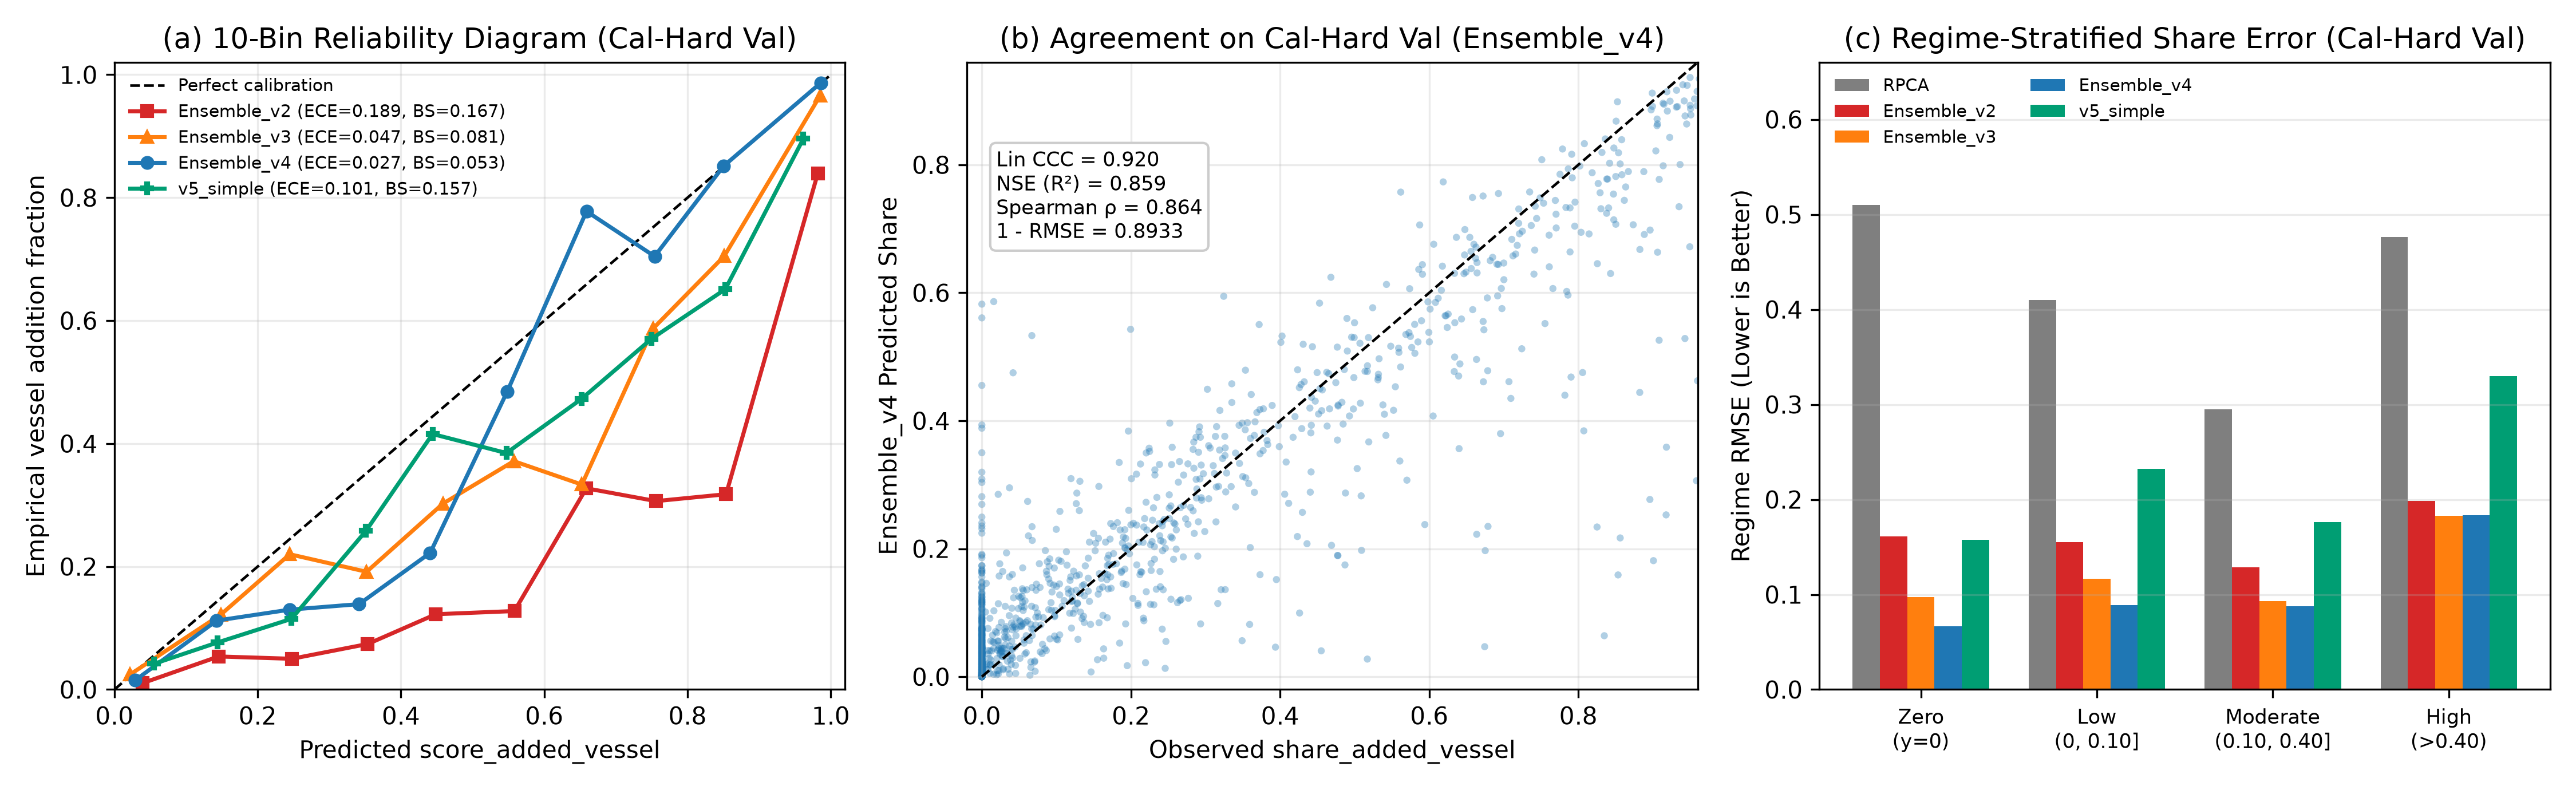

Figure 2 · Hydrophone Tilt Stress, Hard Strata & Unseen Holdout Sites


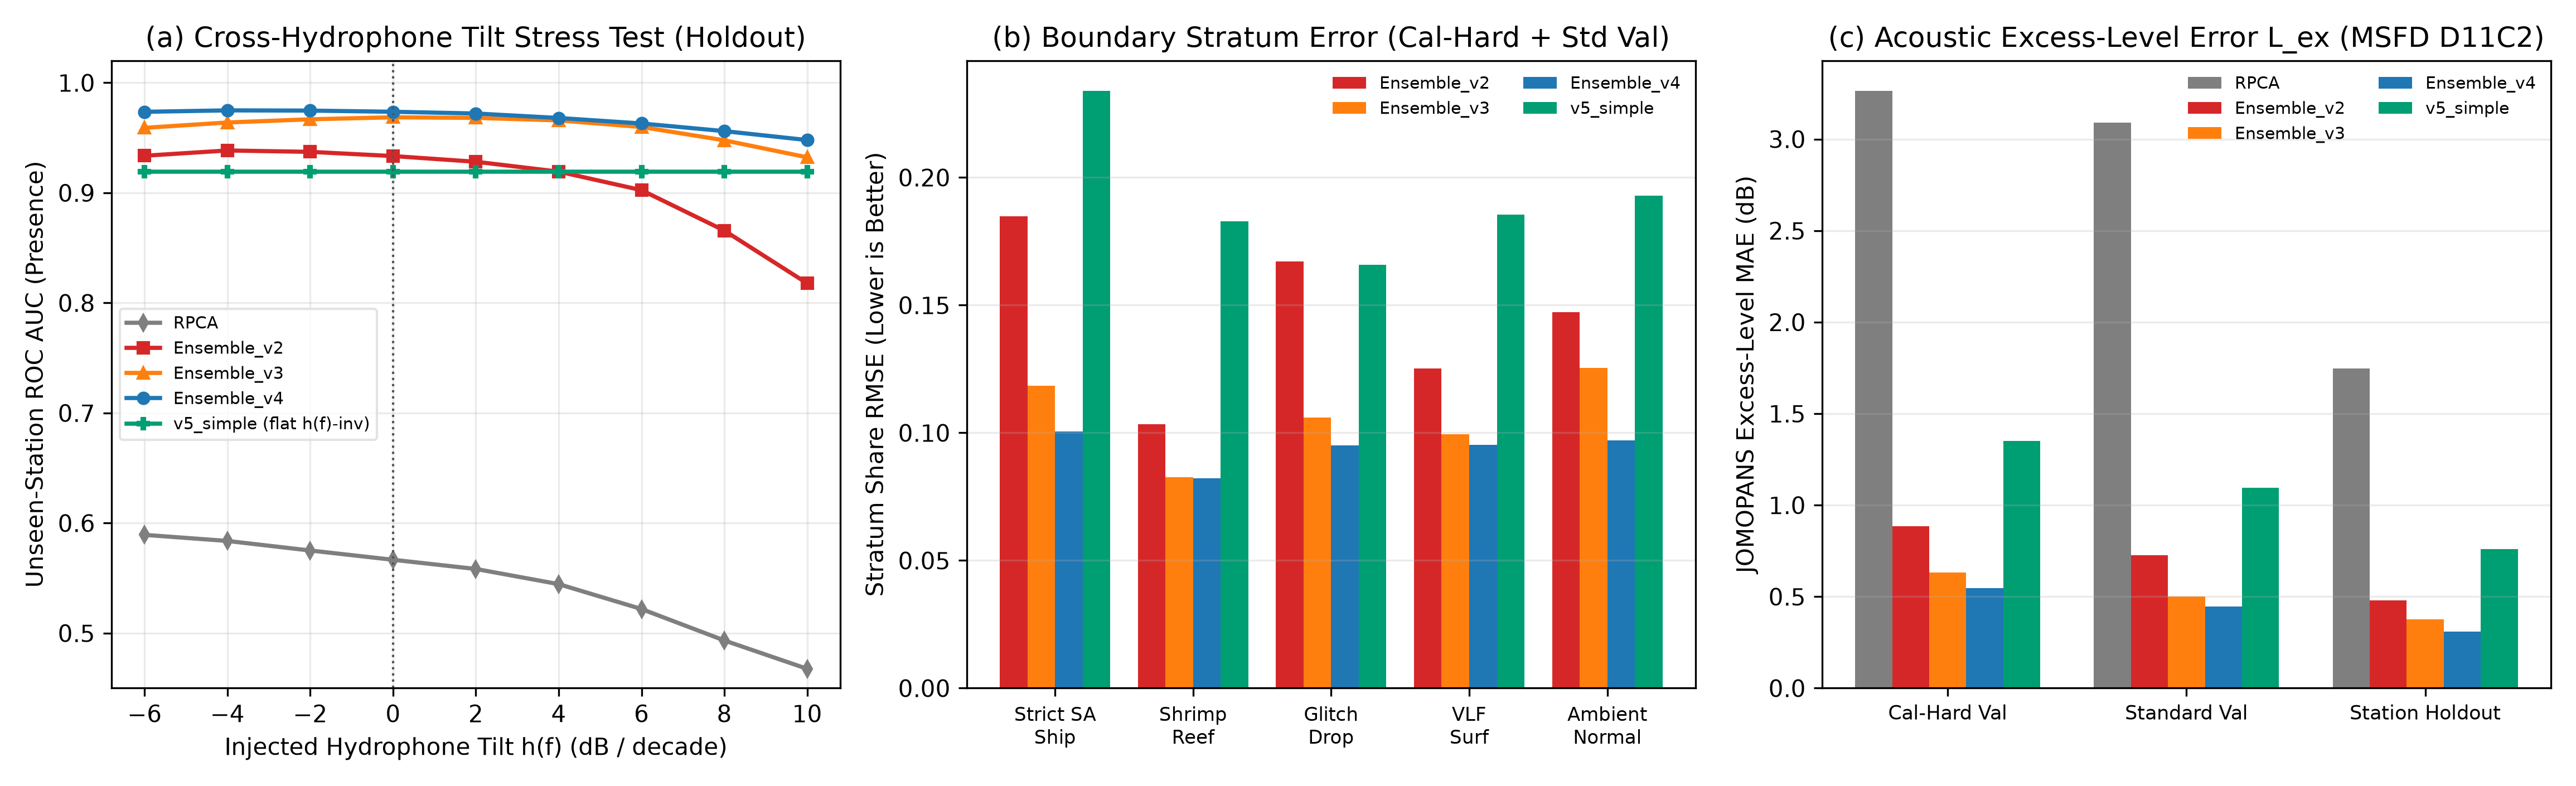

Figure 3 · Acoustic Signal Boundaries (ISO 18405, PCEN & RPCA Decomposition)


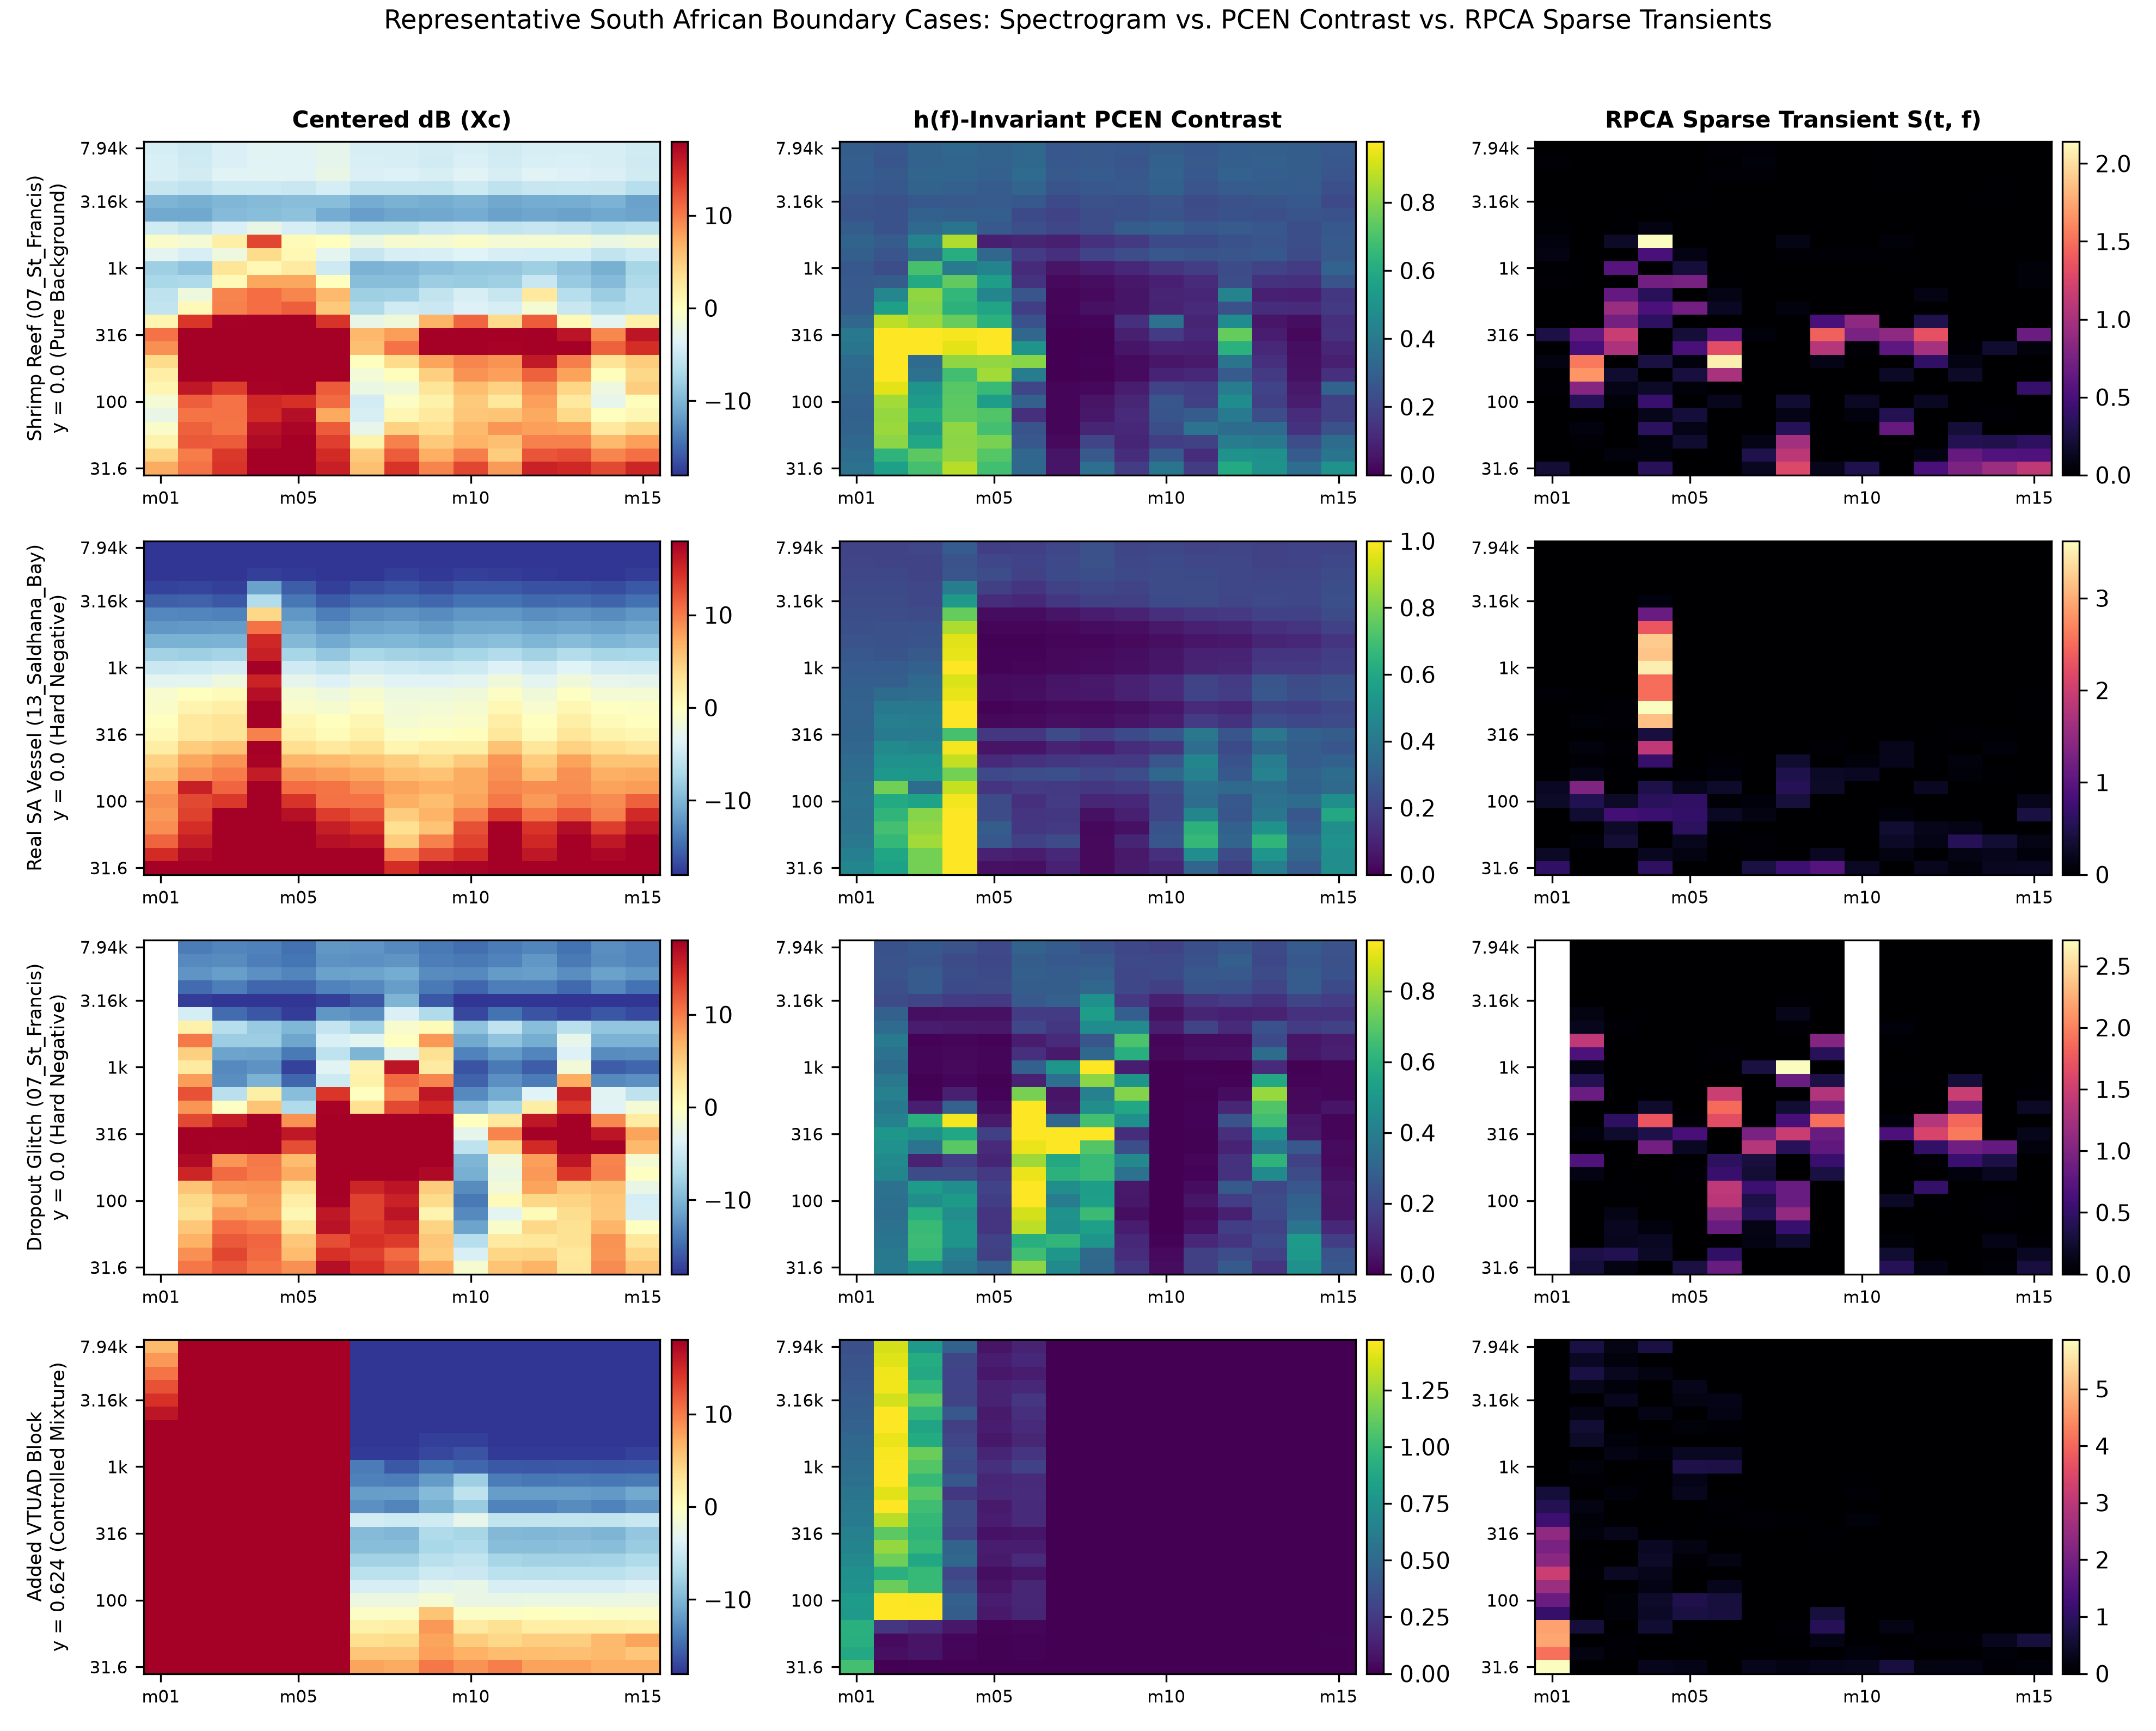

In [7]:
for title, rel in [
    ("Figure 1 · Standards Agreement, JOMOPANS L_excess & Calibration", "reports/standards_benchmark/figures/fig1_standards_calibration_and_agreement.png"),
    ("Figure 2 · Hydrophone Tilt Stress, Hard Strata & Unseen Holdout Sites", "reports/standards_benchmark/figures/fig2_boundary_stress_and_calibration_shift.png"),
    ("Figure 3 · Acoustic Signal Boundaries (ISO 18405, PCEN & RPCA Decomposition)", "reports/standards_benchmark/figures/fig3_acoustic_signal_boundaries_decomposition.png"),
]:
    print(title)
    display(Image(filename=str(ROOT / rel), width=880))


## 6. End-to-End Reproducibility Verification (`v2`, `v3`, `v4`, `v5_simple`)

Every submission artifact is audited below against `sample_submission.csv` (`1,500` rows, exact `ID` order, finite values in `[0, 1]`, SHA-256 checksums). I also reload both `models/v4/bundle_v4.joblib` and `models/v5_simple/bundle_v5_simple.joblib` from disk to verify finite predictions, `+37.5 dB` shift invariance (`v4`), and exact `+10 dB/dec + 4 dB ripple + 27.5 dB` invariance (`v5_simple`).


In [8]:
sample = pd.read_csv(ROOT / "data/zindi/raw/sample_submission.csv")
sub_rows = []
subs = {}
for tag, rel in [
    ("candidate_v2_ensemble (Sub #2: 0.7750)", "submissions/candidate_v2_ensemble.csv"),
    ("candidate_v3_ensemble (Intermediate v3)", "submissions/candidate_v3_ensemble.csv"),
    ("candidate_v4_ensemble (Sub #3: 0.7752)", "submissions/candidate_v4_ensemble.csv"),
    ("candidate_v5_simple (Candidate #4: 42 h(f)-inv)", "submissions/candidate_v5_simple.csv"),
]:
    p = ROOT / rel
    df = pd.read_csv(p)
    assert list(df.columns) == list(sample.columns) and len(df) == 1500
    assert (df["ID"] == sample["ID"]).all()
    assert df["share_added_vessel"].between(0.0, 1.0).all()
    assert df["score_added_vessel"].between(0.0, 1.0).all()
    subs[tag] = df
    sha = hashlib.sha256(p.read_bytes()).hexdigest()[:16]
    sub_rows.append({
        "Candidate": tag,
        "Rows": len(df),
        "Share Mean": round(float(df["share_added_vessel"].mean()), 4),
        "Share SD": round(float(df["share_added_vessel"].std()), 4),
        "Score Mean": round(float(df["score_added_vessel"].mean()), 4),
        "Score > 0.95": round(float((df["score_added_vessel"] > 0.95).mean()), 4),
        "SHA-256 (16)": sha,
    })
display(pd.DataFrame(sub_rows))

# Live bundle_v4 reload + +37.5 dB check AND bundle_v5_simple reload + +10 dB/dec + ripple + gain check
bundle_v4 = joblib.load(ROOT / "models/v4/bundle_v4.joblib")
sh_a, sc_a = predict_from_bundle_v4(bundle_v4, X_sub)
sh_b, sc_b = predict_from_bundle_v4(bundle_v4, X_sub + 37.5)
print(
    f"Live bundle_v4 (+37.5 dB) -> Share max|diff|={np.max(np.abs(sh_a - sh_b)):.2e}, "
    f"Score max|diff|={np.max(np.abs(sc_a - sc_b)):.2e}"
)
assert np.max(np.abs(sh_a - sh_b)) < 1e-6 and np.max(np.abs(sc_a - sc_b)) < 1e-6

bundle_v5 = joblib.load(ROOT / "models/v5_simple/bundle_v5_simple.joblib")
warp_v5 = (10.0 * LOG10_F_NORM + 4.0 * np.cos(2.0 * np.pi * NORM_BAND_COORD * 1.3 + 0.5) + 27.5)[None, None, :]
sh_5a, sc_5a = predict_from_bundle_v5_simple(bundle_v5, X_sub)
sh_5b, sc_5b = predict_from_bundle_v5_simple(bundle_v5, X_sub + warp_v5)
print(
    f"Live bundle_v5_simple (+10 dB/dec + 4 dB ripple + 27.5 dB) -> Share max|diff|={np.max(np.abs(sh_5a - sh_5b)):.2e}, "
    f"Score max|diff|={np.max(np.abs(sc_5a - sc_5b)):.2e}"
)
assert np.max(np.abs(sh_5a - sh_5b)) < 1e-3 and np.max(np.abs(sc_5a - sc_5b)) < 1e-6


,Candidate,Rows,Share Mean,Share SD,Score Mean,Score > 0.95,SHA-256 (16)
0,candidate_v2_ensemble (Sub #2: 0.7750),1500,0.2932,0.2174,0.9134,0.6560,afb088e7356b579f
1,candidate_v3_ensemble (Intermediate v3),1500,0.2732,0.2171,0.8203,0.4907,883e5dae60cb4826
2,candidate_v4_ensemble (Sub #3: 0.7752),1500,0.2764,0.2239,0.8571,0.5900,e8cf38a590b8318e
3,candidate_v5_simple (Candidate #4: 42 h(f)-inv),1500,0.2534,0.1840,0.7239,0.2840,d163e749b707d6cb


Live bundle_v4 (+37.5 dB) -> Share max|diff|=0.00e+00, Score max|diff|=0.00e+00
Live bundle_v5_simple (+10 dB/dec + 4 dB ripple + 27.5 dB) -> Share max|diff|=0.00e+00, Score max|diff|=1.11e-16


## 7. Held-Out South African Site-Level Relative Acoustic Activity & Observed-Signal Support (Zindi Staff Compliance)

Per official Zindi staff spatial-rubric guidance (`daniil_zindi`, 24 Nov 2026), an uninterpolated total-sound map provides context only. Below, I load `reports/standards_benchmark/sa_site_relative_vessel_activity.csv` and `reports/standards_benchmark/sa_heldout_signal_support.csv` (generated strictly over **17,487 held-out real 15-minute windows** across `6` future development periods and `2` unseen holdout sites `09_Fish_Hoek` & `10_Sea_Point`, with zero training or `Test.csv` overlap), contrast `h(f)`-invariant **relative acoustic activity** against total-sound Baseline `B0` and analytical `Physics_Robust_q20` with **1,000-draw calendar-day block bootstrap 95% CIs**, and display the upgraded 3-panel **Figure 2**.


,display_name,eval_scope,windows_heldout,calendar_days,provisional_low_days,rel_vessel_activity_pct,rel_ci95_low_pct,rel_ci95_high_pct,total_sound_median_db,physics_q20_mean_share,ensemble_v4_mean_share
0,Richards Bay,heldout_period_val,10054,143,False,6.2065,5.2503,7.2795,82.4797,0.5794,0.0162
1,Durban,heldout_period_val,2496,26,False,3.3253,2.2837,4.3670,71.6492,0.4149,0.0257
2,Bird Island,heldout_period_val,312,7,False,1.2821,0.0000,2.6981,91.1979,0.5617,0.0071
3,St Croix,heldout_period_val,2354,51,False,1.1895,0.6795,1.8570,72.7468,0.3437,0.0160
4,St Francis,heldout_period_val,525,22,False,18.2857,13.5219,23.2955,88.2053,0.8070,0.0079
5,Fish Hoek,unseen_site_holdout,297,4,True,1.0101,0.0000,2.8846,69.0520,0.4102,0.0240
6,Sea Point,unseen_site_holdout,244,3,True,3.2787,1.7857,4.3478,56.9772,0.4269,0.0122
7,Saldanha Bay,heldout_period_val,1205,14,False,5.3112,3.4543,7.5681,64.3512,0.5278,0.0156
8,Cape Recife,excluded_lt15min,0,0,True,NaN,NaN,NaN,NaN,NaN,NaN
9,Riy Banks,excluded_lt15min,0,0,True,NaN,NaN,NaN,NaN,NaN,NaN


,scope,stratum,n_windows,obs_vlf_peak_r_db,obs_mf_peak_r_db,obs_hf_peak_r_db,physics_q20_share,ensemble_v2_share,ensemble_v4_share,ensemble_v4_score
0,all_heldout_8_sites,strict_hf_ship,120,18.42,25.40,19.29,0.8454,0.0683,0.0363,0.1206
1,all_heldout_8_sites,reef_active,243,14.88,11.66,2.92,0.7382,0.0391,0.0084,0.0812
2,all_heldout_8_sites,glitch_drop,125,18.94,30.98,21.12,0.8316,0.0164,0.0053,0.0209
3,all_heldout_8_sites,vlf_surf,437,19.06,9.46,4.84,0.7975,0.0198,0.0089,0.0688
4,all_heldout_8_sites,ambient_normal,1416,6.55,4.72,2.50,0.3270,0.0484,0.0182,0.1329
5,unseen_sites_fish_hoek_sea_point,strict_hf_ship,11,17.60,19.20,14.84,0.7653,0.0707,0.0345,0.2058
6,unseen_sites_fish_hoek_sea_point,reef_active,3,11.62,8.14,8.20,0.7003,0.0293,0.0019,0.0433
7,unseen_sites_fish_hoek_sea_point,glitch_drop,11,34.98,31.84,19.12,0.7314,0.0404,0.0049,0.0156
8,unseen_sites_fish_hoek_sea_point,vlf_surf,125,24.42,3.78,2.02,0.7796,0.0207,0.0093,0.0939
9,unseen_sites_fish_hoek_sea_point,ambient_normal,391,5.82,5.12,2.66,0.2813,0.0603,0.0218,0.1811


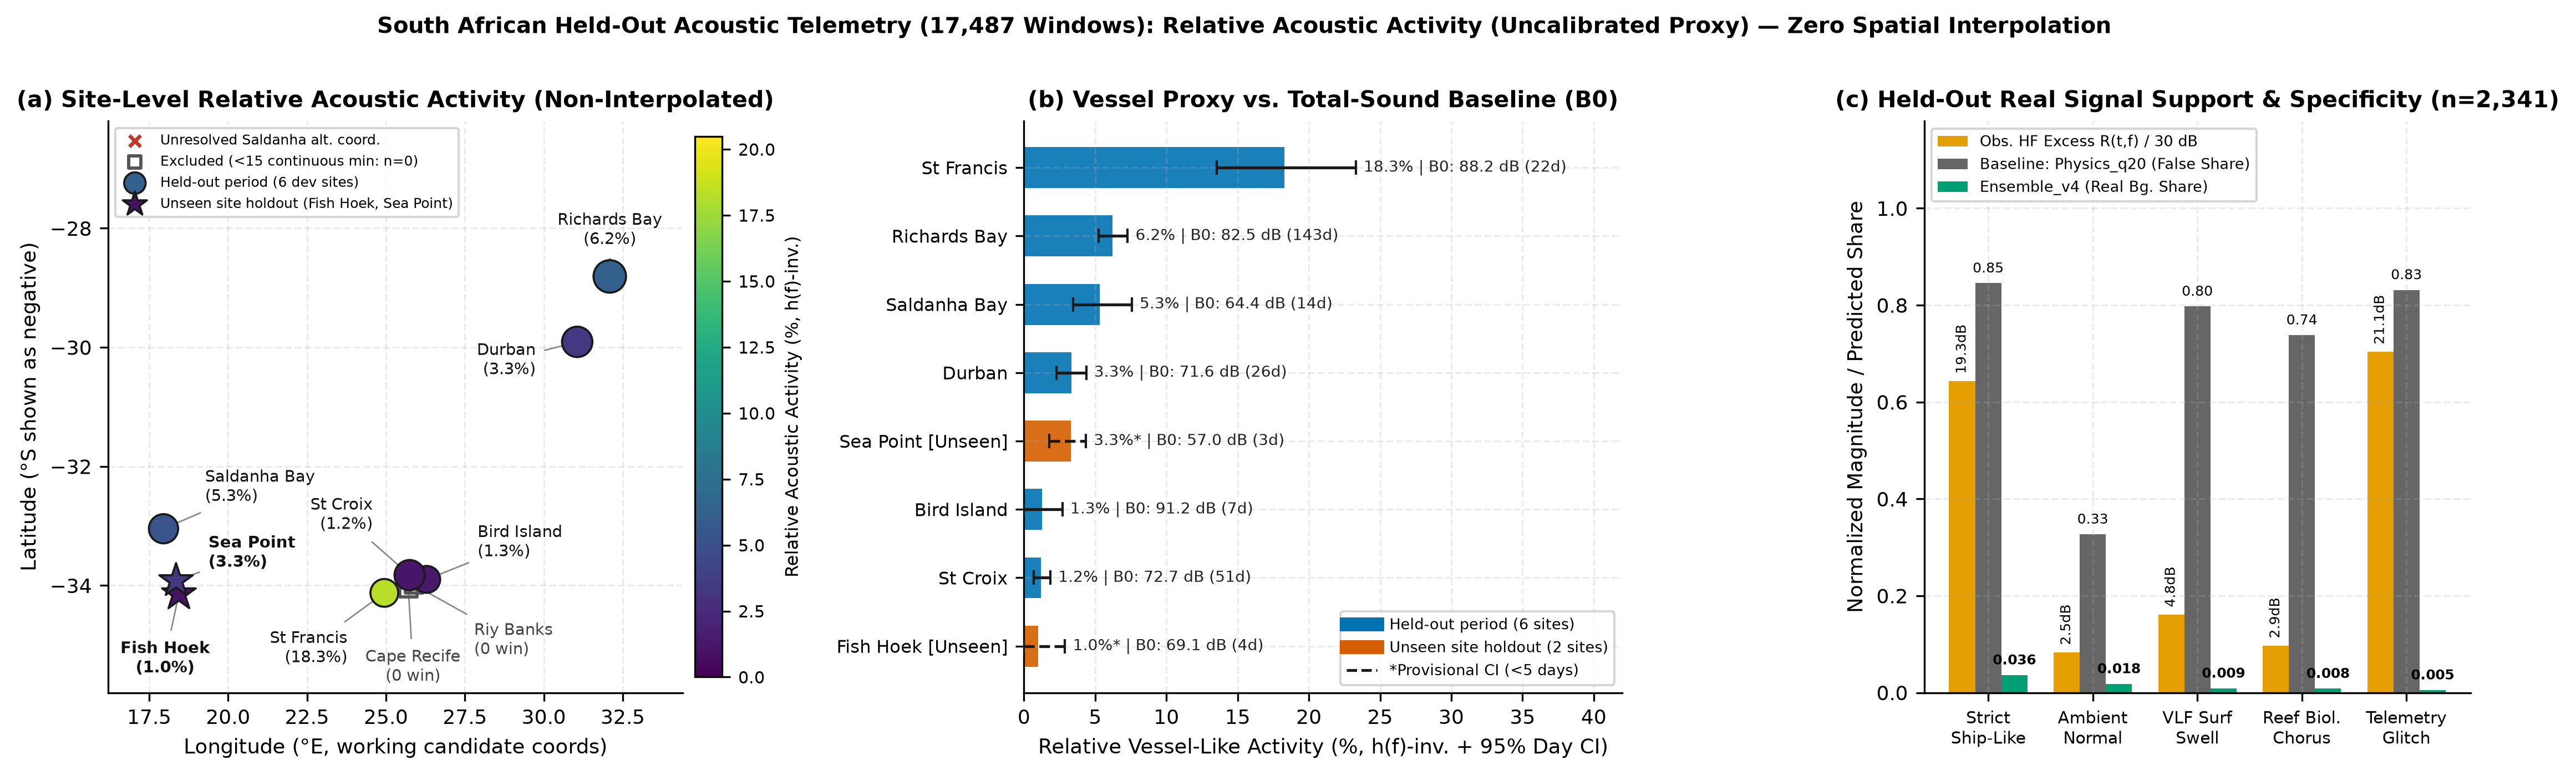

In [9]:
sa_site = pd.read_csv(ROOT / "reports/standards_benchmark/sa_site_relative_vessel_activity.csv")
sa_sup = pd.read_csv(ROOT / "reports/standards_benchmark/sa_heldout_signal_support.csv")
display(sa_site[[
    "display_name", "eval_scope", "windows_heldout", "calendar_days", "provisional_low_days",
    "rel_vessel_activity_pct", "rel_ci95_low_pct", "rel_ci95_high_pct",
    "total_sound_median_db", "physics_q20_mean_share", "ensemble_v4_mean_share"
]].round(4))
display(sa_sup.round(4))
display(Image(filename=str(ROOT / "reports/standards_benchmark/figures/fig2_site_relative_acoustic_activity_map.png"), width=920))
